In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, models, callbacks
from keras.utils import to_categorical
from sklearn.model_selection import KFold

os.makedirs('models', exist_ok=True)
np.random.seed(42)
tf.random.set_seed(42)

(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()
X_train_cnn = X_train_raw.reshape((-1, 28, 28, 1)).astype('float32') / 255.0
X_test_cnn = X_test_raw.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

y_train_cat = to_categorical(y_train_raw, 10)
y_test_cat = to_categorical(y_test_raw, 10)


In [2]:
def build_simple_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (5, 5), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_simple = build_simple_cnn()
model_simple.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=5, batch_size=200, verbose=1)
score_simple = model_simple.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Точність Simple CNN: {score_simple[1]*100:.2f}%")


Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9316 - loss: 0.2383 - val_accuracy: 0.9761 - val_loss: 0.0734
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9794 - loss: 0.0715 - val_accuracy: 0.9839 - val_loss: 0.0483
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9848 - loss: 0.0511 - val_accuracy: 0.9859 - val_loss: 0.0420
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9879 - loss: 0.0403 - val_accuracy: 0.9874 - val_loss: 0.0380
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9901 - loss: 0.0323 - val_accuracy: 0.9881 - val_loss: 0.0354
Точність Simple CNN: 98.81%


In [3]:
def build_deeper_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(30, (5, 5), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(15, (3, 3), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(50, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_deeper = build_deeper_cnn()
model_deeper.fit(X_train_cnn, y_train_cat, validation_data=(X_test_cnn, y_test_cat), epochs=5, batch_size=200, verbose=1)
score_deeper = model_deeper.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Точність Deeper CNN: {score_deeper[1]*100:.2f}%")


Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8839 - loss: 0.3774 - val_accuracy: 0.9742 - val_loss: 0.0807
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9707 - loss: 0.0973 - val_accuracy: 0.9817 - val_loss: 0.0549
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9784 - loss: 0.0696 - val_accuracy: 0.9848 - val_loss: 0.0435
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9817 - loss: 0.0578 - val_accuracy: 0.9882 - val_loss: 0.0356
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9853 - loss: 0.0487 - val_accuracy: 0.9892 - val_loss: 0.0307
Точність Deeper CNN: 98.92%


In [4]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
subset_size = 5000
X_sub = X_train_cnn[:subset_size]
y_sub = y_train_cat[:subset_size]

for fold, (train_idx, val_idx) in enumerate(kfold.split(X_sub, y_sub), 1):
    m = build_deeper_cnn()
    m.fit(X_sub[train_idx], y_sub[train_idx], epochs=2, batch_size=128, verbose=0)
    _, acc = m.evaluate(X_sub[val_idx], y_sub[val_idx], verbose=0)
    cv_scores.append(acc)
    print(f"Fold {fold}: Точність = {acc*100:.2f}%")

print(f"\nСередня точність 5-Fold CV: {np.mean(cv_scores)*100:.2f}% (± {np.std(cv_scores)*100:.2f}%)")


Fold 1: Точність = 91.50%
Fold 2: Точність = 92.20%
Fold 3: Точність = 89.00%
Fold 4: Точність = 89.70%
Fold 5: Точність = 89.20%

Середня точність 5-Fold CV: 90.32% (± 1.29%)


In [5]:
def build_improved_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_improved = build_improved_cnn()
history_improved = model_improved.fit(
    X_train_cnn, y_train_cat,
    validation_data=(X_test_cnn, y_test_cat),
    epochs=6, batch_size=200, verbose=1
)

score_improved = model_improved.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"\nФінальна точність Improved CNN: {score_improved[1]*100:.2f}%")

best_path = 'models/cnn_mnist_best.keras'
model_improved.save(best_path)
print(f"Модель успішно збережено у: {best_path}")


Epoch 1/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9307 - loss: 0.2271 - val_accuracy: 0.9813 - val_loss: 0.1822
Epoch 2/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9778 - loss: 0.0740 - val_accuracy: 0.9860 - val_loss: 0.0461
Epoch 3/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9835 - loss: 0.0548 - val_accuracy: 0.9905 - val_loss: 0.0288
Epoch 4/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9856 - loss: 0.0455 - val_accuracy: 0.9903 - val_loss: 0.0285
Epoch 5/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9868 - loss: 0.0421 - val_accuracy: 0.9899 - val_loss: 0.0274
Epoch 6/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9895 - loss: 0.0347 - val_accuracy: 0.9909 - val_loss: 0.0268

Фінальна точність Improved CNN: 99.09%
Модель успішно збережено у: models/cnn_mnist_best.keras


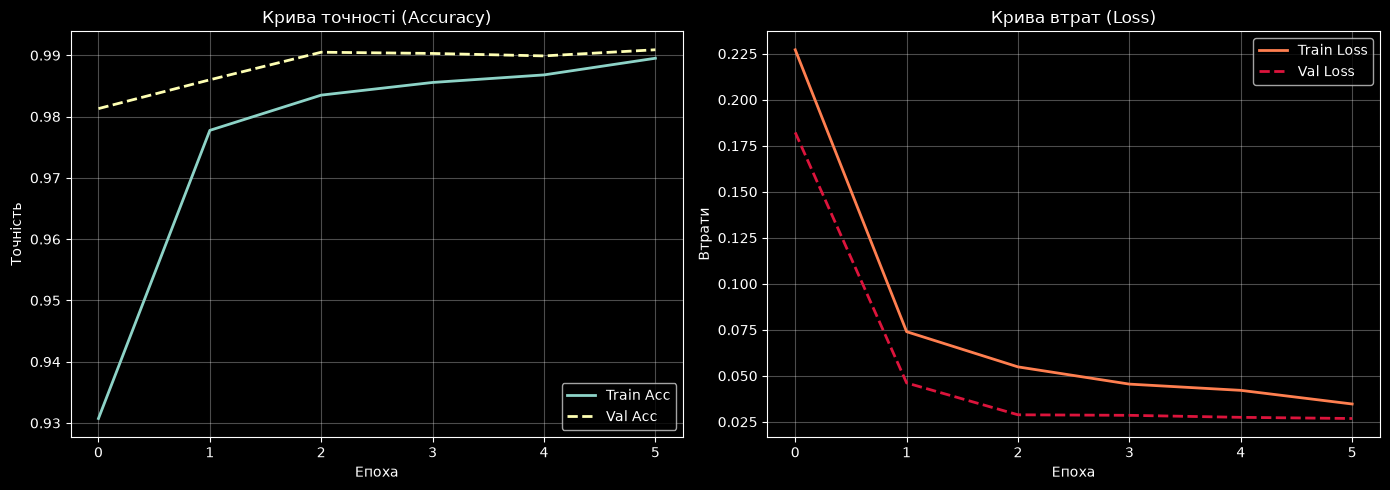

In [6]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_improved.history['accuracy'], label='Train Acc', lw=2)
plt.plot(history_improved.history['val_accuracy'], label='Val Acc', lw=2, linestyle='--')
plt.title('Крива точності (Accuracy)')
plt.xlabel('Епоха'); plt.ylabel('Точність'); plt.legend(); plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_improved.history['loss'], label='Train Loss', lw=2, color='coral')
plt.plot(history_improved.history['val_loss'], label='Val Loss', lw=2, linestyle='--', color='crimson')
plt.title('Крива втрат (Loss)')
plt.xlabel('Епоха'); plt.ylabel('Втрати'); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
